<a href="https://colab.research.google.com/github/oguilherme-barreto/Calculo_Numerico/blob/main/Atividade_Gauss_Seidel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
def gauss_seidel(tol=1e-5, max_iter=1000):
    # Aproximacao inicial
    x, y, z = 0.0, 0.0, 0.0

    for k in range(1, max_iter + 1):
        # Valores da iteracao anterior
        x_ant, y_ant, z_ant = x, y, z

        # Metodo de Gauss-Seidel
        x = (6 + y_ant - 2*z_ant) / 10
        y = (22 + x + z_ant) / 11
        z = (-10 - 2*x + y) / 10

        # Norma infinito da diferenca entre iteracoes
        erro = max(
            abs(x - x_ant),
            abs(y - y_ant),
            abs(z - z_ant)
        )

        if erro < tol:
            return k, x, y, z, erro

    return None


k, x, y, z, erro = gauss_seidel()

print("Numero de iteracoes:", k)
print(f"x = {x:.8f}")
print(f"y = {y:.8f}")
print(f"z = {z:.8f}")
print(f"Erro final = {erro:.8e}")

Numero de iteracoes: 6
x = 1.00000003
y = 1.99999998
z = -1.00000001
Erro final = 1.26260694e-06


In [2]:
import pandas as pd

def gauss_seidel(tol=1e-5, max_iter=1000):
    # Aproximacao inicial
    x, y, z = 0.0, 0.0, 0.0

    # Armazena os resultados das iteracoes
    resultados = [{
        'k': 0,
        'x(k)': x,
        'y(k)': y,
        'z(k)': z,
        'Norma infinito': None
    }]

    # Metodo iterativo de Gauss-Seidel
    for k in range(1, max_iter + 1):

        # Valores da iteracao anterior
        x_ant, y_ant, z_ant = x, y, z

        # Calcula as novas aproximacoes
        x = (6 + y_ant - 2*z_ant) / 10
        y = (22 + x + z_ant) / 11
        z = (-10 - 2*x + y) / 10

        # Calcula a norma infinito
        erro = max(
            abs(x - x_ant),
            abs(y - y_ant),
            abs(z - z_ant)
        )

        # Armazena os resultados da iteracao atual
        resultados.append({
            'k': k,
            'x(k)': x,
            'y(k)': y,
            'z(k)': z,
            'Norma infinito': erro
        })

        # Verifica o criterio de parada
        if erro < tol:
            break
    else:
        raise RuntimeError("O metodo nao convergiu.")

    # Retorna a solucao, o numero de iteracoes e os resultados
    return x, y, z, k, erro, resultados


# Executa o metodo apenas uma vez
x, y, z, k, erro, resultados = gauss_seidel()

# Questao 5: apresenta a solucao aproximada
print("QUESTAO 5 - RESULTADOS")
print(f"Numero de iteracoes: {k}")
print(f"x = {x:.8f}")
print(f"y = {y:.8f}")
print(f"z = {z:.8f}")
print(f"Erro final = {erro:.8e}")

# Questao 6: gera a tabela com os resultados armazenados
tabela = pd.DataFrame(resultados)

print("\nQUESTAO 6 - TABELA DE ITERACOES")
print(tabela.to_string(
    index=False,
    formatters={
        'x(k)': '{:.8f}'.format,
        'y(k)': '{:.8f}'.format,
        'z(k)': '{:.8f}'.format,
        'Norma infinito': lambda v:
            '-' if pd.isna(v) else f'{v:.8e}'
    }
))

# Opcional: salva a tabela em arquivo CSV
tabela.to_csv('resultados_gauss_seidel.csv', index=False)

QUESTAO 5 - RESULTADOS
Numero de iteracoes: 6
x = 1.00000003
y = 1.99999998
z = -1.00000001
Erro final = 1.26260694e-06

QUESTAO 6 - TABELA DE ITERACOES
 k       x(k)       y(k)        z(k) Norma infinito
 0 0.00000000 0.00000000  0.00000000            NaN
 1 0.60000000 2.05454545 -0.91454545 2.05454545e+00
 2 0.98836364 2.00671074 -0.99700165 3.88363636e-01
 3 1.00007140 2.00027907 -0.99998637 1.17077686e-02
 4 1.00002518 2.00000353 -1.00000468 2.75540414e-04
 5 1.00000129 1.99999969 -1.00000029 2.38921647e-05
 6 1.00000003 1.99999998 -1.00000001 1.26260694e-06


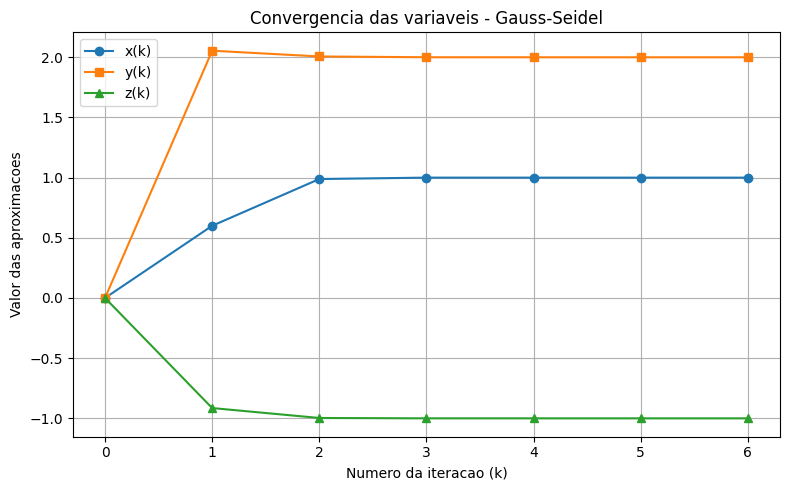

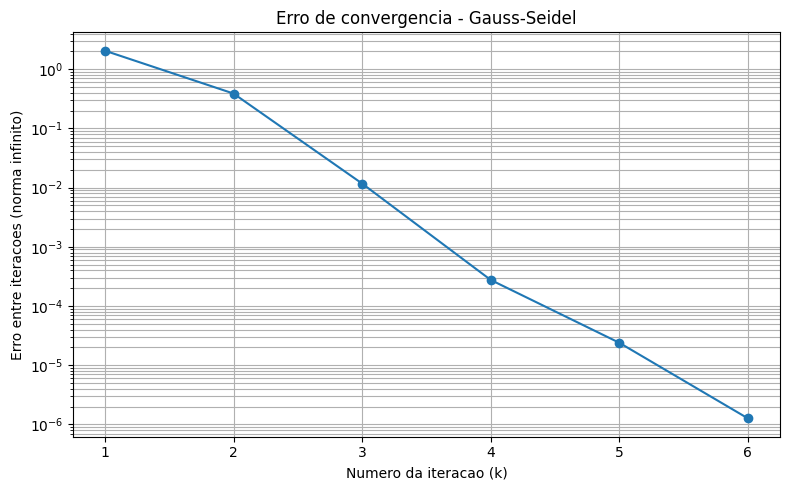

In [3]:
import matplotlib.pyplot as plt
import pandas as pd

# Converte os resultados armazenados em tabela
tabela = pd.DataFrame(resultados)

# Dados das iteracoes
k = tabela['k']
x = tabela['x(k)']
y = tabela['y(k)']
z = tabela['z(k)']
erro = tabela['Norma infinito']

# ==========================================
# Grafico (a): x(k), y(k) e z(k) por iteracao
# ==========================================

plt.figure(figsize=(8, 5))

plt.plot(k, x, marker='o', label='x(k)')
plt.plot(k, y, marker='s', label='y(k)')
plt.plot(k, z, marker='^', label='z(k)')

plt.xlabel('Numero da iteracao (k)')
plt.ylabel('Valor das aproximacoes')
plt.title('Convergencia das variaveis - Gauss-Seidel')
plt.xticks(k)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# ==========================================
# Grafico (b): erro em escala logaritmica
# ==========================================

# Remove a iteracao inicial, que nao possui erro
dados_erro = tabela.dropna(subset=['Norma infinito'])

plt.figure(figsize=(8, 5))

plt.semilogy(
    dados_erro['k'],
    dados_erro['Norma infinito'],
    marker='o',
    linestyle='-'
)

plt.xlabel('Numero da iteracao (k)')
plt.ylabel('Erro entre iteracoes (norma infinito)')
plt.title('Erro de convergencia - Gauss-Seidel')
plt.xticks(dados_erro['k'])
plt.grid(True, which='both')
plt.tight_layout()
plt.show()